# Group 20 · Week 6 최종 DML — 한강 대여소·왕복 이용 비율 (쉬는날/근무일 분리)
담당: 성원제 · 입력: `data/Group20_통합데이터_v3_final.xlsx` (시우 v3, 수식 값 고정본)

**질문**: 여가 이용자는 미세먼지에 더 반응하는가?
- ① 주 검정: Y = R500 = ln(한강500 대여) − ln(그외500 대여)
- ② 왕복 검정: Y = R2 = ln(왕복) − ln(편도)

**설정 (사전 고정, 결과 보고 바꾸지 않음)**
- Partially linear DML, 처치 D = PM2.5 / 10 (µg/m³), 5-fold cross-fitting, seed 5개 중앙값 (Chernozhukov et al. 2018 집계)
- 학습기: Random Forest, Gradient Boosting · 습도 포함/제외 둘 다 보고
- 통제: Week 4 노트북(`Group20_W4_MapA_DML_EN.ipynb`)의 `Xmat`과 동일 — 기온, 강수량, 강수일, 풍속, 적설, Day_Off, 요일, 월, day-of-year, 연도, 추세 t, (습도)
- 학습기 하이퍼파라미터도 Week 4와 동일 (RF 500 trees, min_samples_leaf=5 / GB 300 trees, depth 3, lr 0.05, subsample 0.8)
- 재현 확인: 서울 전체 RF·습도포함 = −0.32% (Week 4 보고 −0.315%; v2→v3 데이터 갱신에 따른 미세 차이)
- 표본: 727일 (풍속 결측 3일 + 2025-02-28 절단일 제외) → 쉬는날 241일, 근무일 486일
- 쉬는날−근무일 차이 = θ쉬는날 − θ근무일, SE = √(SE₁² + SE₂²)
- θ는 로그비율 단위 → % 변화 = 100·(e^θ − 1)

※ v3 엑셀의 R 열은 수식이라 캐시값이 없어서, 같은 정의로 Python에서 다시 계산함 (구성합 검증 포함).

In [1]:
import numpy as np, pandas as pd
def load(path="../data/Group20_통합데이터_v3_final.xlsx"):
    d = pd.read_excel(path, sheet_name="통합_서울일별")
    d = d.rename(columns={"일시":"date","따릉이 하루 총 이용건수":"total","서울 PM2.5 일평균 (㎍/㎥)":"pm25",
        "PM2.5 분류":"pm_cat","평균기온(°C)":"temp","평균 풍속(m/s)":"wind","평균 상대습도(%)":"humid",
        "공휴일 더미 (0=아님,1=공휴일)":"holiday","합계 일조시간(hr)":"sun","합계 일사량(MJ/m2)":"solar",
        "평균 전운량(1/10)":"cloud","한강500_대여":"h500","그외500_대여":"o500","위치미상_대여":"unk",
        "한강1km_대여":"h1k","그외1km_대여":"o1k","한강500_panel_대여":"h500p","그외500_panel_대여":"o500p",
        "한강500_noTrib_대여":"h500nt","그외500_noTrib_대여":"o500nt","왕복":"rt","편도":"ow"})
    d["date"] = pd.to_datetime(d["date"])
    # recompute formula columns (Excel formulas have no cached values)
    d["rain_mm"] = d["일강수량(mm)"].fillna(0.0)
    d["rain_day"] = (d["rain_mm"] >= 0.1).astype(int)
    d["snow_cm"] = d["일 최심신적설(cm)"].fillna(0.0)
    d["weekend"] = d["주말 더미 (0=평일,1=주말)"].astype(int)
    d["Day_Off"] = ((d["weekend"]==1)|(d["holiday"]==1)).astype(int)
    lr = lambda a,b: np.log(d[a]) - np.log(d[b])
    d["R500"]=lr("h500","o500"); d["R1km"]=lr("h1k","o1k"); d["R500_panel"]=lr("h500p","o500p")
    d["R500_noTrib"]=lr("h500nt","o500nt"); d["R2"]=lr("rt","ow")
    d["ln_h500"]=np.log(d["h500"]); d["ln_total"]=np.log(d["total"])
    d["pm10u"] = d["pm25"]/10.0          # treatment in 10 µg/m3 units
    d["trend"] = np.arange(len(d))   # Week 4: t = row index (no gaps → same as day count)
    d["doy"] = d["date"].dt.dayofyear
    d["dow"] = d["date"].dt.dayofweek; d["month"]=d["date"].dt.month; d["year"]=d["date"].dt.year
    d["doy_sin"]=np.sin(2*np.pi*d["date"].dt.dayofyear/365.25); d["doy_cos"]=np.cos(2*np.pi*d["date"].dt.dayofyear/365.25)
    return d


In [2]:
d = load()
assert len(d)==731 and d.date.is_unique
assert (d.h500+d.o500+d.unk-d.total).abs().max()==0 and (d.h1k+d.o1k+d.unk-d.total).abs().max()==0
base = d[(d.truncated_flag==0) & d.wind.notna()]
print("분석 표본:", len(base), "| 쉬는날", int(base.Day_Off.sum()), "| 근무일", int((base.Day_Off==0).sum()))
print("한강500 대여 비중 평균: %.2f%%" % (100*(base.h500/base.total).mean()), "| 왕복 비중 평균: %.2f%%" % (100*(base.rt/(base.rt+base.ow)).mean()))

분석 표본: 727 | 쉬는날 241 | 근무일 486
한강500 대여 비중 평균: 6.03% | 왕복 비중 평균: 7.01%


## DML 엔진

In [3]:
import numpy as np, pandas as pd
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import KFold
from scipy import stats

# Week 4 notebook spec (Xmat): temp, rain_mm, rain_day, wind, snow_cm, Day_Off, dow_n, mon, doy, year, t (+humid)
BASE = ["temp","rain_mm","rain_day","wind","snow_cm","Day_Off","dow","month","doy","year","trend"]
HUM = ["humid"]
SUNX = ["sun","solar","cloud"]

def learner(kind, seed):
    if kind == "RF":
        return RandomForestRegressor(n_estimators=500, min_samples_leaf=5, random_state=seed, n_jobs=-1)
    return GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3,
                                     subsample=0.8, random_state=seed)

def nw_var(psi, L=None):
    """Newey-West long-run variance of psi (already ordered by date)."""
    n = len(psi); psi = psi - psi.mean()
    if L is None: L = int(np.floor(4*(n/100)**(2/9)))
    v = psi @ psi / n
    for l in range(1, L+1):
        w = 1 - l/(L+1); v += 2*w*(psi[l:] @ psi[:-l])/n
    return v

def plr_once(y, dtr, X, kind, seed, folds="random", k=5):
    n = len(y); uy = np.zeros(n); vd = np.zeros(n)
    kf = KFold(k, shuffle=(folds=="random"), random_state=seed if folds=="random" else None)
    for tr, te in kf.split(X):
        ml = learner(kind, seed).fit(X[tr], y[tr]); uy[te] = y[te] - ml.predict(X[te])
        mm = learner(kind, seed).fit(X[tr], dtr[tr]); vd[te] = dtr[te] - mm.predict(X[te])
    theta = (vd @ uy) / (vd @ vd)
    J = np.mean(vd**2); psi = (uy - theta*vd)*vd
    se = np.sqrt(np.mean(psi**2)/J**2/n)
    se_hac = np.sqrt(nw_var(psi)/J**2/n)
    r2y = 1 - np.sum(uy**2)/np.sum((y-y.mean())**2)
    r2d = 1 - np.sum(vd**2)/np.sum((dtr-dtr.mean())**2)
    return theta, se, se_hac, r2y, r2d

def dml(df, ycol, controls, kind="RF", seeds=(0,1,2,3,4), folds="random", treat="pm10u"):
    df = df.dropna(subset=[ycol, treat]+controls).sort_values("date")
    y = df[ycol].to_numpy(float); dtr = df[treat].to_numpy(float); X = df[controls].to_numpy(float)
    res = np.array([plr_once(y, dtr, X, kind, s, folds) for s in seeds])
    th = np.median(res[:,0])
    # Chernozhukov et al. (2018) median aggregation across splits
    se = np.sqrt(np.median(res[:,1]**2 + (res[:,0]-th)**2))
    se_hac = np.sqrt(np.median(res[:,2]**2 + (res[:,0]-th)**2))
    z = th/se; p = 2*(1-stats.norm.cdf(abs(z))); p_hac = 2*(1-stats.norm.cdf(abs(th/se_hac)))
    return dict(n=len(y), theta=th, se=se, ci_lo=th-1.96*se, ci_hi=th+1.96*se, p=p,
                se_hac=se_hac, p_hac=p_hac, r2_y=np.median(res[:,3]), r2_d=np.median(res[:,4]),
                theta_min=res[:,0].min(), theta_max=res[:,0].max())

def diff(a, b, hac=False):
    k = "se_hac" if hac else "se"
    d = a["theta"]-b["theta"]; se = np.sqrt(a[k]**2 + b[k]**2)
    return dict(diff=d, se=se, ci_lo=d-1.96*se, ci_hi=d+1.96*se, p=2*(1-stats.norm.cdf(abs(d/se))))

pct = lambda t: 100*(np.exp(t)-1)


## 전체 실행 (핵심 → 보강 → 일조 추가 → 시간순 fold)  · 약 20분

In [4]:
import pickle, time
d = load()
base = d[(d.truncated_flag==0) & d.wind.notna()]           # 727 days (as in Week 5)
subs = {"쉬는날": base[base.Day_Off==1], "근무일": base[base.Day_Off==0]}
rows = []
def run(block, y, sub, kind, ctrl_name, controls, folds="random", data=None):
    t=time.time(); r = dml(data if data is not None else subs[sub], y, controls, kind, folds=folds)
    r.update(block=block, y=y, sample=sub, learner=kind, controls=ctrl_name, folds=folds)
    rows.append(r); print(f"[{block}] {y:12s} {sub} {kind} {ctrl_name:10s} {folds:6s} n={r['n']} θ={r['theta']:+.4f} se={r['se']:.4f} p={r['p']:.3f} ({time.time()-t:.0f}s)", flush=True)
    pickle.dump(rows, open("results.pkl","wb"))

C_H = BASE+HUM; C_noH = BASE
# 1) CORE
for y in ("R500","R2"):
    for sub in subs:
        for kind in ("RF","GB"):
            run("핵심", y, sub, kind, "습도포함", C_H)
            run("핵심", y, sub, kind, "습도제외", C_noH)
# 2) ROBUSTNESS outcomes (humidity included = primary spec)
for y in ("R1km","R500_panel","R500_noTrib","ln_h500"):
    for sub in subs:
        for kind in ("RF","GB"):
            run("보강", y, sub, kind, "습도포함", C_H)
# 3) Sunshine/solar/cloud added: city-wide (same 725-day sample before & after) and core outcomes
s725 = base.dropna(subset=SUNX)
for kind in ("RF","GB"):
    for hname, hc in (("습도포함",HUM),("습도제외",[])):
        run("일조추가", "ln_total", "전체", kind, hname, BASE+hc, data=s725)
        run("일조추가", "ln_total", "전체", kind, hname+"+일조", BASE+hc+SUNX, data=s725)
for y in ("R500","R2"):
    for sub in subs:
        for kind in ("RF","GB"):
            run("일조추가", y, sub, kind, "습도포함+일조", C_H+SUNX, data=subs[sub].dropna(subset=SUNX))
# 4) Time-ordered folds
for y in ("R500","R2"):
    for sub in subs:
        for kind in ("RF","GB"):
            run("시간순fold", y, sub, kind, "습도포함", C_H, folds="time")
for kind in ("RF","GB"):
    run("시간순fold", "ln_total", "전체", kind, "습도포함", C_H, folds="time", data=base)
    run("기준(전체)", "ln_total", "전체", kind, "습도포함", C_H, data=base)
print("DONE")


[핵심] R500         쉬는날 RF 습도포함       random n=241 θ=-0.0091 se=0.0093 p=0.331 (37s)


[핵심] R500         쉬는날 RF 습도제외       random n=241 θ=-0.0089 se=0.0088 p=0.315 (39s)


[핵심] R500         쉬는날 GB 습도포함       random n=241 θ=-0.0058 se=0.0085 p=0.497 (11s)


[핵심] R500         쉬는날 GB 습도제외       random n=241 θ=-0.0076 se=0.0070 p=0.276 (10s)


[핵심] R500         근무일 RF 습도포함       random n=486 θ=-0.0117 se=0.0030 p=0.000 (38s)


...

[시간순fold] ln_total     전체 RF 습도포함       time   n=727 θ=-0.0142 se=0.0084 p=0.090 (46s)


[기준(전체)] ln_total     전체 RF 습도포함       random n=727 θ=-0.0032 se=0.0078 p=0.679 (46s)


[시간순fold] ln_total     전체 GB 습도포함       time   n=727 θ=+0.0047 se=0.0072 p=0.510 (18s)


[기준(전체)] ln_total     전체 GB 습도포함       random n=727 θ=+0.0029 se=0.0074 p=0.699 (19s)


DONE


## 결과 요약

In [5]:
import pandas as pd, numpy as np
R = pd.DataFrame(rows)
R["효과(%)"]=pct(R.theta); R["CI하한(%)"]=pct(R.ci_lo); R["CI상한(%)"]=pct(R.ci_hi)
show = ["block","y","sample","learner","controls","folds","n","theta","se","ci_lo","ci_hi","p","p_hac","r2_y","r2_d","효과(%)"]
pd.set_option("display.width",200); R[show].round(4)

,block,y,sample,learner,controls,folds,n,theta,se,ci_lo,ci_hi,p,p_hac,r2_y,r2_d,효과(%)
0,핵심,R500,쉬는날,RF,습도포함,random,241,-0.0091,0.0093,-0.0274,0.0092,0.3315,0.3916,0.7575,0.3295,-0.9031
1,핵심,R500,쉬는날,RF,습도제외,random,241,-0.0089,0.0088,-0.0262,0.0084,0.3145,0.3539,0.7608,0.2909,-0.8845
2,핵심,R500,쉬는날,GB,습도포함,random,241,-0.0058,0.0085,-0.0226,0.0110,0.4974,0.5247,0.7896,0.3370,-0.5785
3,핵심,R500,쉬는날,GB,습도제외,random,241,-0.0076,0.0070,-0.0212,0.0061,0.2757,0.3188,0.7702,0.2829,-0.7553
4,핵심,R500,근무일,RF,습도포함,random,486,-0.0117,0.0030,-0.0177,-0.0058,0.0001,0.0001,0.8260,0.4404,-1.1672
5,핵심,R500,근무일,RF,습도제외,random,486,-0.0114,0.0031,-0.0175,-0.0052,0.0003,0.0005,0.8149,0.4195,-1.1314
6,핵심,R500,근무일,GB,습도포함,random,486,-0.0114,0.0027,-0.0167,-0.0061,0.0000,0.0001,0.8417,0.4693,-1.1379
7,핵심,R500,근무일,GB,습도제외,random,486,-0.0115,0.0029,-0.0172,-0.0057,0.0001,0.0002,0.8249,0.4160,-1.1407
8,핵심,R2,쉬는날,RF,습도포함,random,241,-0.0037,0.0061,-0.0157,0.0083,0.5450,0.5645,0.6459,0.3295,-0.3691
9,핵심,R2,쉬는날,RF,습도제외,random,241,-0.0023,0.0058,-0.0137,0.0090,0.6870,0.7173,0.6455,0.2909,-0.2329


In [6]:
# 쉬는날 − 근무일 차이
out=[]
for (b,y,k,c,f),g in R[R["sample"].isin(["쉬는날","근무일"])].groupby(["block","y","learner","controls","folds"]):
    if len(g)<2: continue
    a=g[g["sample"]=="쉬는날"].iloc[0].to_dict(); w=g[g["sample"]=="근무일"].iloc[0].to_dict()
    dd=diff(a,w); out.append(dict(block=b,y=y,learner=k,controls=c,folds=f,**{k2:round(v,4) for k2,v in dd.items()}))
pd.DataFrame(out)

,block,y,learner,controls,folds,diff,se,ci_lo,ci_hi,p
0,보강,R1km,GB,습도포함,random,0.0001,0.0062,-0.0120,0.0122,0.9845
1,보강,R1km,RF,습도포함,random,-0.0001,0.0062,-0.0124,0.0121,0.9825
2,보강,R500_noTrib,GB,습도포함,random,0.0063,0.0084,-0.0103,0.0228,0.4573
3,보강,R500_noTrib,RF,습도포함,random,0.0035,0.0098,-0.0157,0.0228,0.7199
4,보강,R500_panel,GB,습도포함,random,0.0033,0.0087,-0.0138,0.0205,0.7017
5,보강,R500_panel,RF,습도포함,random,-0.0006,0.0099,-0.0199,0.0188,0.9547
6,보강,ln_h500,GB,습도포함,random,-0.0019,0.0249,-0.0506,0.0468,0.9390
7,보강,ln_h500,RF,습도포함,random,-0.0108,0.0243,-0.0585,0.0370,0.6586
8,시간순fold,R2,GB,습도포함,time,0.0034,0.0074,-0.0111,0.0178,0.6468
9,시간순fold,R2,RF,습도포함,time,-0.0060,0.0073,-0.0203,0.0082,0.4053


## 신뢰구간 그림

figs ok


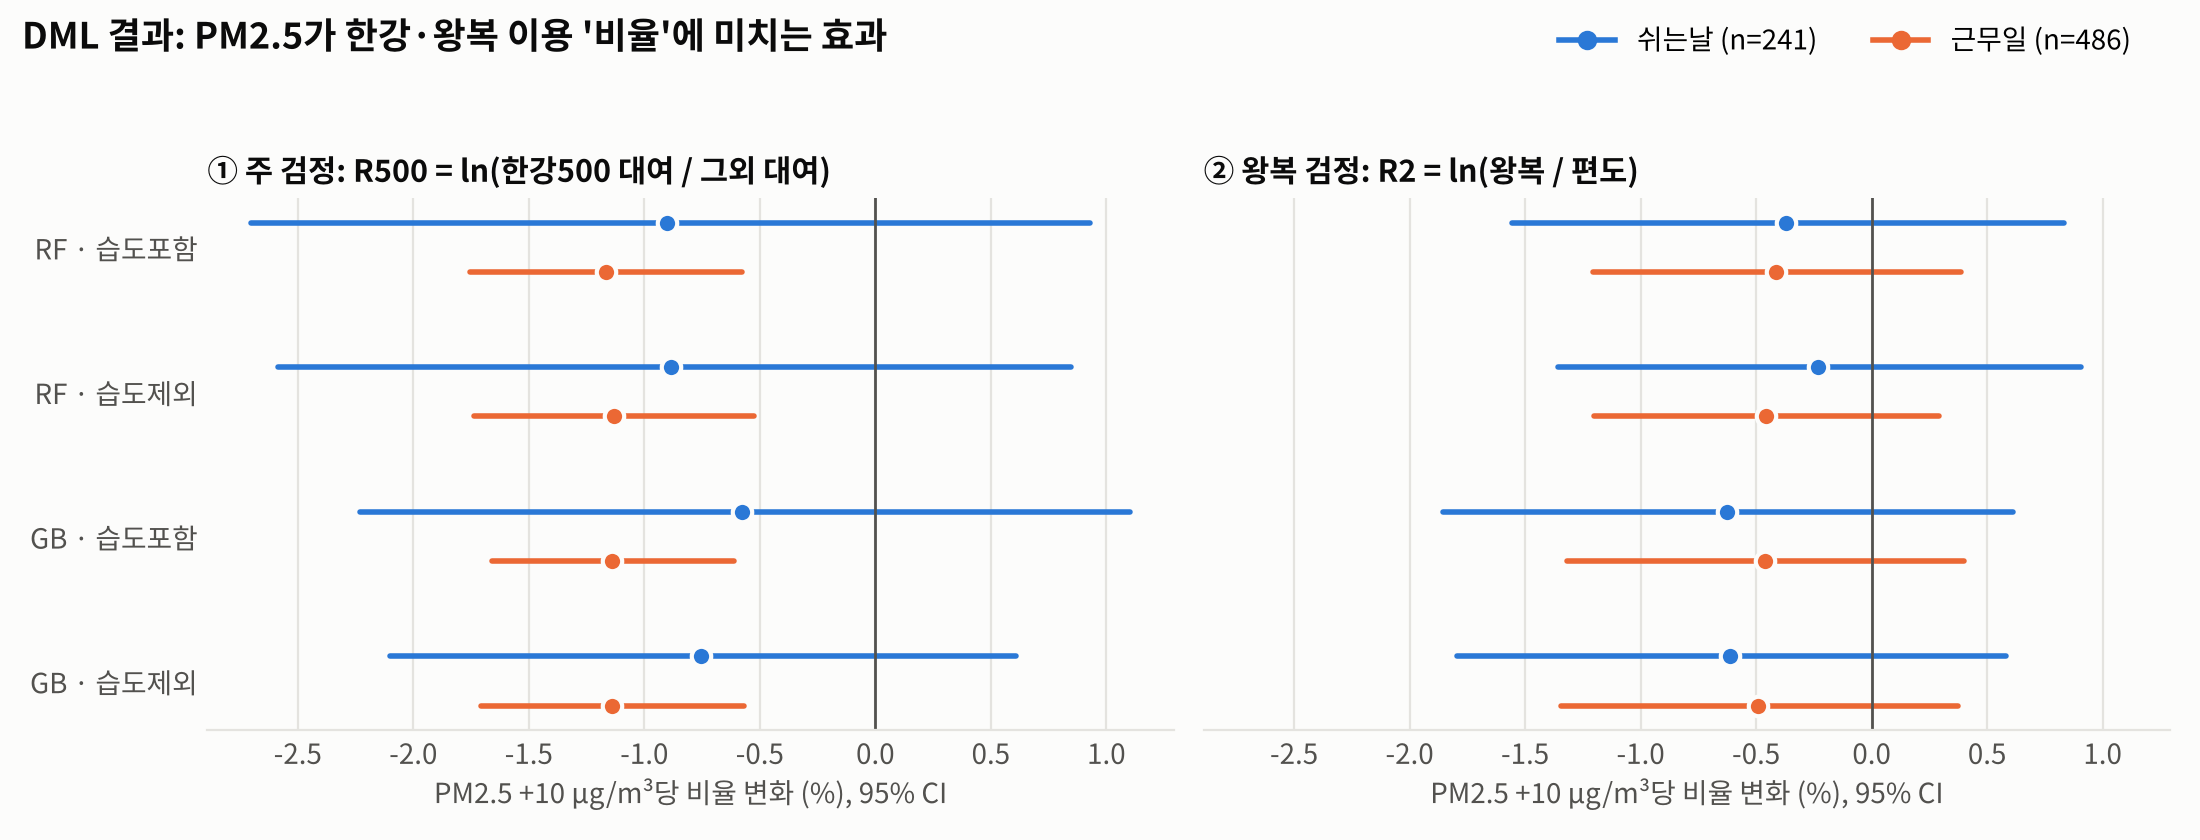

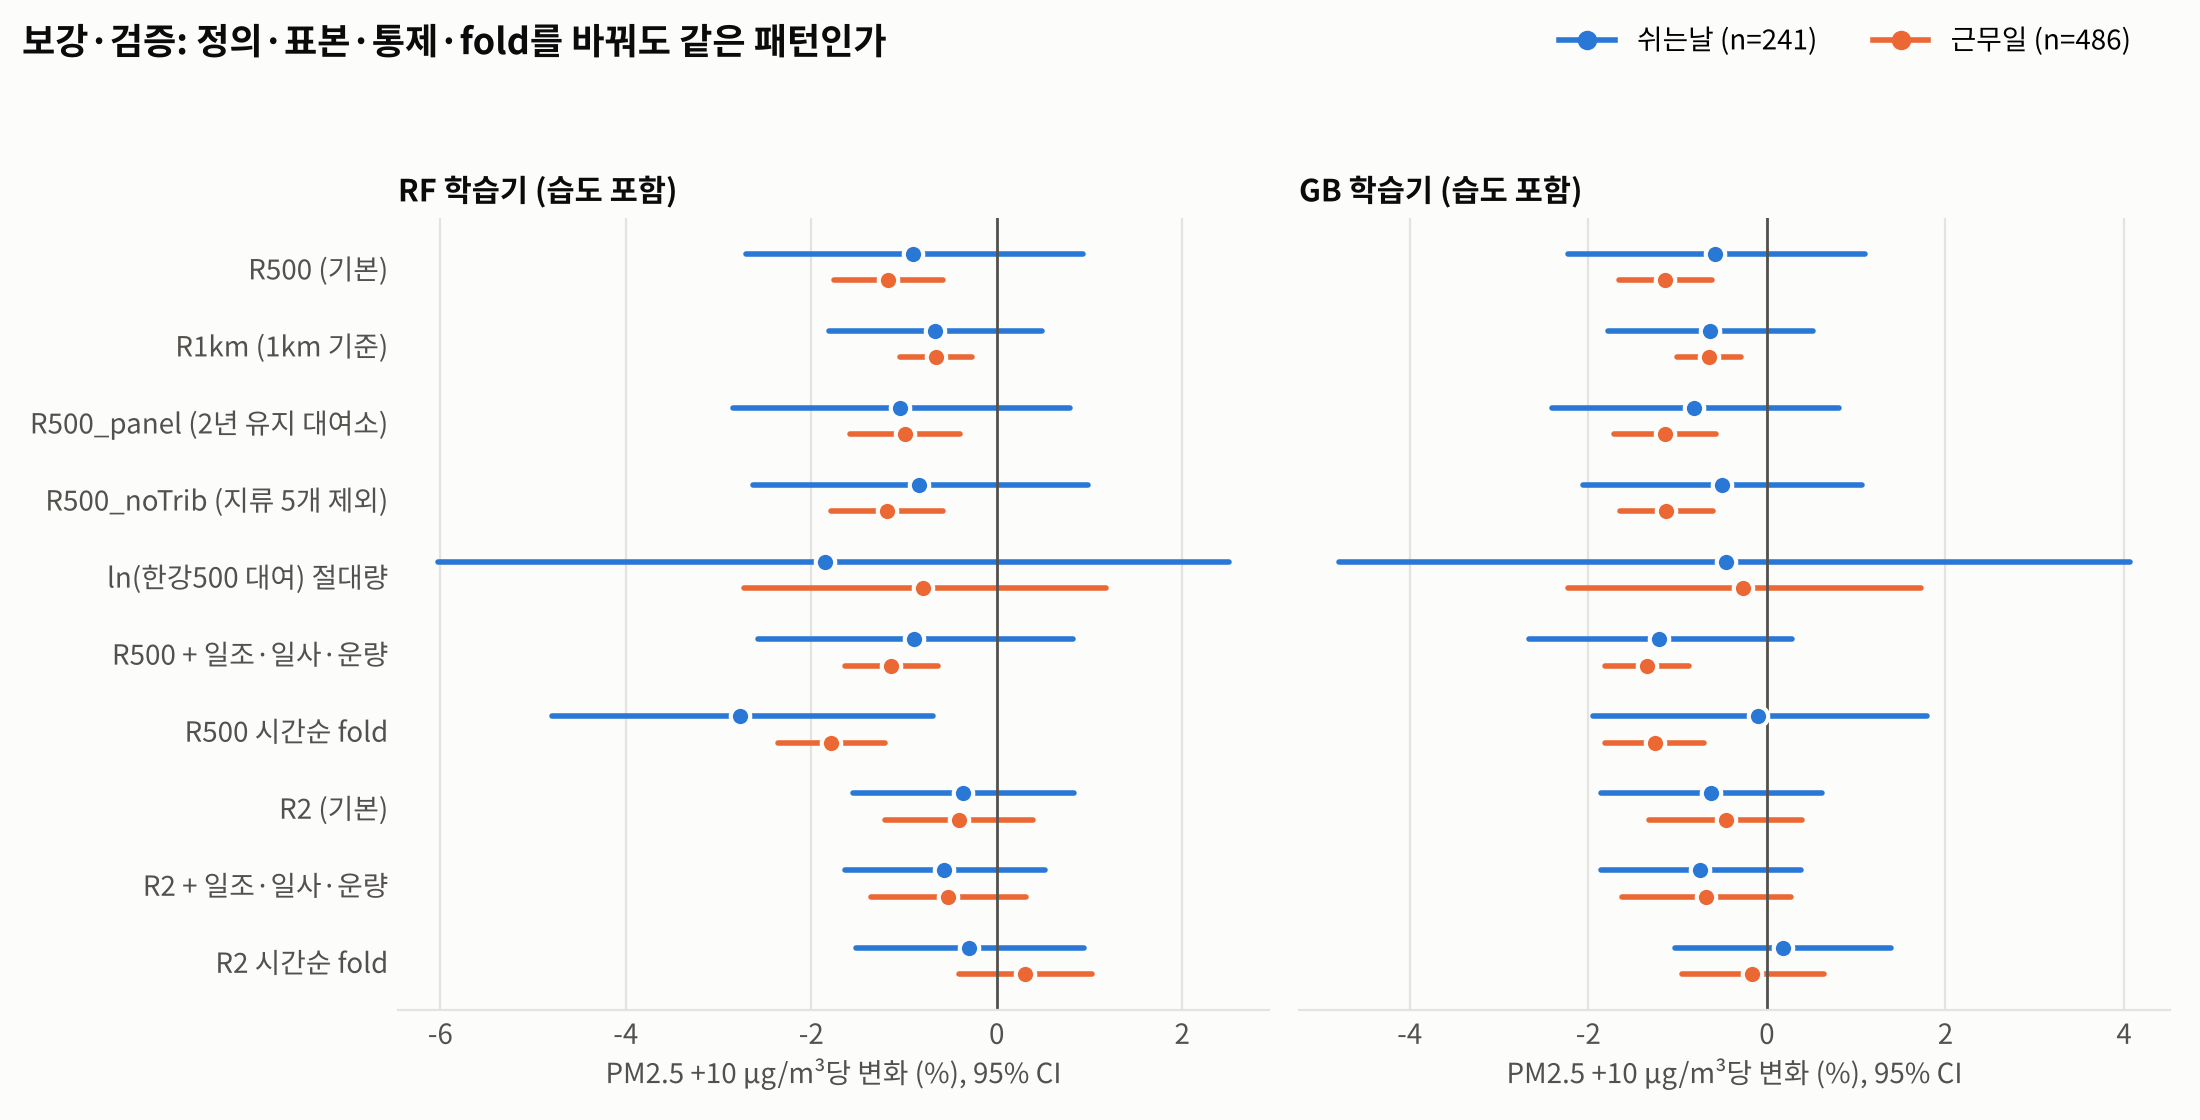

In [7]:
exec(open("make_fig.py").read())
from IPython.display import Image, display
display(Image("fig_core_ci.png")); display(Image("fig_robust_ci.png"))